In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.visualization import plot_histogram
from scipy.optimize import minimize
from qiskit.circuit.library import RZGate, RZZGate, RXXGate, RYYGate, RXGate, MCXGate
import pandas as pd
import networkx as nx
from qiskit.circuit import QuantumCircuit, Parameter
from qiskit_aer import AerSimulator
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer.primitives  import EstimatorV2, SamplerV2  
from qiskit_ibm_runtime import Session
from typing import Dict, Optional, Tuple 
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.quantum_info import SparsePauliOp, Pauli


In [2]:
def build_binding_interaction_graph(pocket_pharms, ligand_pharms, tau):
    G = nx.Graph()
    allowed_matches = {
        'H': {'H'},
        'D': {'D'},
        'A': {'A'},
    }

    nodes = []
    for p in pocket_pharms:
        for L in ligand_pharms:
            if L['type'] in allowed_matches.get(p['type'], set()):
                nid = f"P{p['id']}_L{L['id']}"
                G.add_node(
                    nid,
                    pocket_id=p['id'],
                    ligand_id=L['id'],
                    phc_type=(p['type'], L['type']),
                    coord_p=np.array(p['coord']),
                    coord_l=np.array(L['coord'])
                )
                nodes.append(nid)

    n = len(nodes)
    for i in range(n):
        for j in range(i+1, n):
            u = nodes[i]
            v = nodes[j]
            pu = G.nodes[u]['coord_p']
            pv = G.nodes[v]['coord_p']
            lu = G.nodes[u]['coord_l']
            lv = G.nodes[v]['coord_l']

            if np.array_equal(pu, pv) or np.array_equal(lu, lv):
                continue
            
            d_p = np.linalg.norm(pu - pv)
            d_l = np.linalg.norm(lu - lv)
            
            if abs(d_p - d_l) <= tau:
                G.add_edge(u, v)
    

    return G

In [3]:
ligand_pharms_Novo = [
    {'id': 1, 'type': 'A', 'coord': (-2.98700,        0.21200,       -0.15600)},
    {'id': 2, 'type': 'A', 'coord': (1.21000,       0.95500,        1.95900)},
    {'id': 3, 'type': 'A', 'coord': (3.20800,       -0.82400,       -1.27100)},
    {'id': 4, 'type': 'A', 'coord': (-4.09100,      -0.48500,       -2.17000)},
    {'id': 5, 'type': 'A', 'coord': (-5.79500,       -2.13200,       -0.54400)},
    {'id': 6, 'type': 'A', 'coord': (-7.19700,        0.03800,        0.60300)},
    {'id': 7, 'type': 'A', 'coord': (10.91700,        0.37700,        2.56800)},
    
    {'id': 9, 'type': 'D', 'coord': (4.18800,       -0.81100,       -1.19800)},
    {'id': 10, 'type': 'D', 'coord': (-5.61600,       -2.17200,       -1.50300)},
    {'id': 11, 'type': 'D', 'coord': (11.61300,        0.41500,        1.89500)}, 
    {'id': 12, 'type': 'D', 'coord': (4.95300,        0.69200,        2.01700)},
    {'id': 13, 'type': 'D', 'coord': (-9.09300,       -0.45900,        1.88700)},
    {'id': 14, 'type': 'D', 'coord': (-8.42600,       -0.20900,        3.48700)},
    {'id': 15, 'type': 'H', 'coord': (-1.56900,        1.23300,        2.05200)},
    {'id': 16, 'type': 'H', 'coord': (-4.13600,        1.97100,       -2.18400)}, 
    {'id': 17, 'type': 'H', 'coord': (-5.29000,        0.60000,       -3.89200)}, 
    {'id': 18, 'type': 'H', 'coord': (-0.22470,       -0.01880,       -0.21480)}, 
    {'id': 19, 'type': 'H', 'coord': (8.41230,       0.12300,        1.45300)}, 
    {'id': 20, 'type': 'H', 'coord': (11.27970,       -1.11100,       -2.68770)}, 
]


In [4]:
pocket_pharms = [
    {'id': 1, 'type': 'D', 'coord': (199.82860,      197.30280,      141.89060)},
    {'id': 2, 'type': 'H', 'coord': (204.59880,      200.76620,      140.40180)},
    {'id': 3, 'type': 'H', 'coord': (204.17940,      197.86600,      138.26570)},
    {'id': 4, 'type': 'H', 'coord': (201.23680,      198.98520,      136.05630)},
]

In [5]:
tau = 4
G = build_binding_interaction_graph(pocket_pharms, ligand_pharms_Novo, tau)
print(f"Built BIG with {G.number_of_nodes()} nodes and {G.number_of_edges()} edges.")

Built BIG with 24 nodes and 116 edges.


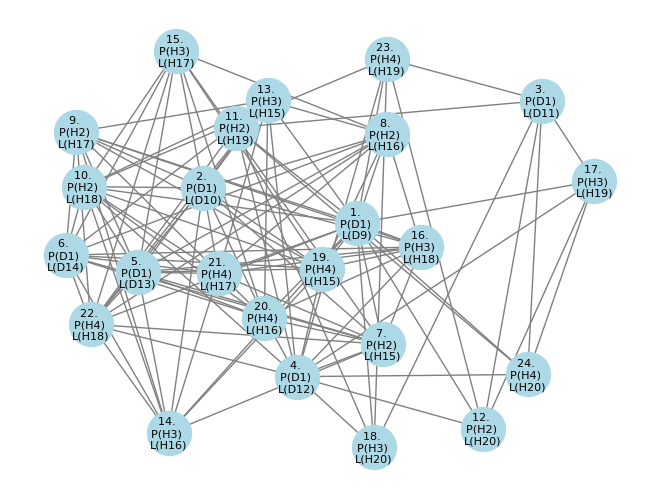

In [6]:
pos  = nx.spring_layout(G, k=2, seed=3)
labels = {
    node: f"{i}. \nP({G.nodes[node]['phc_type'][0]}{G.nodes[node]['pocket_id']}) \nL({G.nodes[node]['phc_type'][1]}{G.nodes[node]['ligand_id']})"
    for i, node in enumerate(G.nodes, start=1)  # start numbering from 1
}

nx.draw(G, pos, with_labels=True, labels=labels, node_color='lightblue', edge_color='grey', node_size=1000, font_size=8)
plt.show()

In [7]:
Gc = nx.complement(G)   

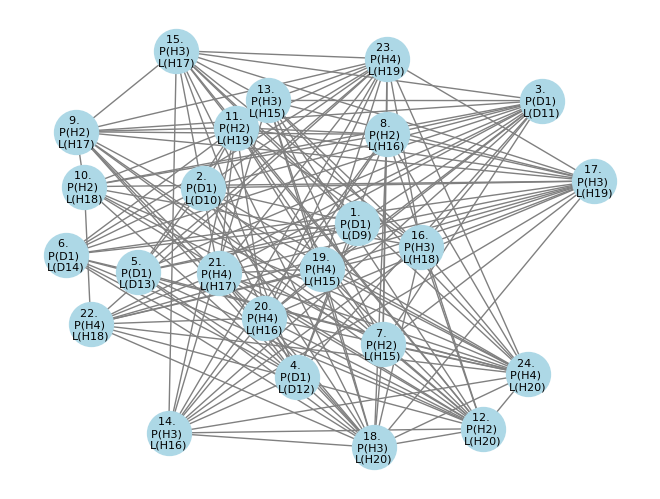

Built BIG with 24 nodes and 160 edges.


In [8]:
#Draw the graph
nx.draw(Gc, pos, with_labels=True, labels=labels,  node_color='lightblue', edge_color='grey', node_size=1000, font_size=8)
plt.show()
print(f"Built BIG with {Gc.number_of_nodes()} nodes and {Gc.number_of_edges()} edges.")

In [9]:
def build_qubo(G, default_node_weight, default_edge_weight, node_weights=None, edge_weights=None):
    n = G.number_of_nodes()
    Q = np.zeros((n, n))
    node_to_idx = {node: idx for idx, node in enumerate(G.nodes())}


    for node in G.nodes():
        w = default_node_weight
        if node_weights and node in node_weights:
            w = node_weights[node]
        idx = node_to_idx[node]
        Q[idx, idx] = w


    for i, j in G.edges():
        w = default_edge_weight
        if edge_weights and (i, j) in edge_weights:
            w = edge_weights[(i, j)]
        idx_i = node_to_idx[i]
        idx_j = node_to_idx[j]
        Q[idx_i, idx_j] = w
        Q[idx_j, idx_i] = w

    return Q


In [11]:
def build_neighbors(Q):

    num_vars = Q.shape[0]
    neighbors = { i: [] for i in range(num_vars) }
    for i in range(num_vars):
        for j in range(num_vars):
            if i != j and Q[i, j] != 0:
                neighbors[i].append(j)
    return neighbors

In [12]:
def apply_local_mixing(qc, target, neighbors, angle, ancilla):
    num_ctrls = len(neighbors)

    if num_ctrls == 0:
        # if no controls, then using just RX
        qc.rx(2 * angle, target)
        return

    for nb in neighbors:
        qc.x(nb)

    # AND(neighbors) -> ancilla
    mcx = MCXGate(num_ctrls)
    qc.append(mcx, neighbors + [ancilla])

    # Controlled-RX
    crx = RXGate(2 * angle).control(1)
    qc.append(crx, [ancilla, target])

    # Uncompute ancilla
    qc.append(mcx, neighbors + [ancilla])
    for nb in neighbors:
        qc.x(nb)


In [13]:
def create_qaoa_circuit(qubo, beta, gamma, neighbors, p):
    
    num_vars = qubo.shape[0]
    qr = QuantumRegister(num_vars+1)
    cr = ClassicalRegister(num_vars)
    qc = QuantumCircuit(qr, cr)

    for layer in range(p):
        for i in range(num_vars):
            for j in range(i, num_vars):
                if qubo[i, j] != 0:
                    if i == j:
                        angle2 = gamma[layer] * qubo[i, j]
                        qc.rz(angle2, i)
                    
        qc.barrier()
        for v in range(num_vars):
            apply_local_mixing(qc, target=v, neighbors=neighbors[v], angle=beta[layer], ancilla=num_vars)
        
        qc.barrier()

    for i in range(num_vars):
        qc.measure(i, i)

    return qc

In [14]:
qubo = build_qubo(
            Gc,
            default_node_weight=-1.0,
            default_edge_weight=3.0,
        )

neighbors = build_neighbors(qubo)

In [17]:
def run_qaoa(beta, gamma):
    qc = create_qaoa_circuit(qubo, beta, gamma, neighbors, p)
    backend = AerSimulator(method="statevector")   
    tqc = transpile(qc, backend, optimization_level=3)
    result = backend.run(tqc, shots=1024).result()
    counts = result.get_counts()
    return counts


In [18]:
def objective(params):
    beta = params[:p]
    gamma = params[p:]
    counts = run_qaoa(beta, gamma)
    energy = 0
    total_counts = sum(counts.values())
    for bitstring, count in counts.items():
        x = np.array([int(bit) for bit in bitstring[::-1]])  
        energy += (x @ qubo @ x.T) * (count / total_counts)
    return energy

In [19]:
import secrets

p = 3  

lambda_max = np.max(np.abs(qubo[np.triu_indices_from(qubo, k=1)]))
gamma_cap = np.pi / (2 * lambda_max)
seed = secrets.randbelow(2**32)
np.random.seed(seed)
init_beta = np.random.uniform(0, np.pi, p)
init_gamma = np.random.uniform(0, np.pi, p)
initial_params = np.concatenate([init_beta, init_gamma])
bounds = [(0, 2 * np.pi)] * p + [(0, np.pi / 2)] * p

# Run optimization
result = minimize(objective, initial_params, method='COBYLA', options={'maxiter': 400})

# Extract optimal parameters
optimal_params = result.x
optimal_beta = optimal_params[:p]
optimal_gamma = optimal_params[p:]
print(f"Optimal beta: {optimal_beta}, Optimal gamma: {optimal_gamma}")

Optimal beta: [1.57016909 3.12828366 3.15791926], Optimal gamma: [-0.19371716  3.62478852  2.09409385]


In [20]:
counts = run_qaoa(optimal_beta, optimal_gamma)
best_bitstring = max(counts, key=counts.get)

best_bitstring = best_bitstring[::-1]
print(f"Optimal bitstring: {best_bitstring}")



Optimal bitstring: 100000100000010000001000


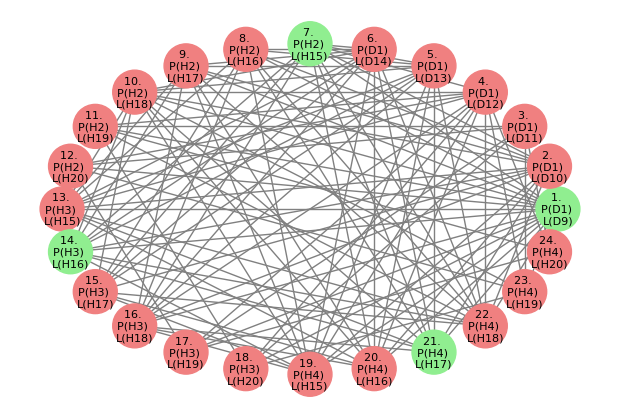

In [22]:
def plot_result(G, bitstring):
    x = [int(char) for char in bitstring]
    #colors = ["tab:red" if i == 0 else "tab:blue" for i in x]
    colors = ["lightcoral" if v==0 else "lightgreen" for v in x]


    def densify_positions(pos, scale=0.6, center=(0.0, 0.0)):
        cx, cy = center            # point you want to shrink toward
        new_pos = {}
        for n, (x, y) in pos.items():
            new_x = cx + (x - cx) * scale
            new_y = cy + (y - cy) * scale
            new_pos[n] = (new_x, new_y)
        return new_pos
    dense_pos = nx.circular_layout(G)
    #nx.visualization.mpl_draw(G, node_color=colors, node_size=100, alpha=0.8, pos=pos)
    plt.figure(figsize=(6, 4))
    nx.draw(G, dense_pos, with_labels=True, labels=labels,  node_color=colors, node_size=1000, edge_color='grey', font_size=8)
    

plot_result(G, best_bitstring)

In [23]:
# p = 1
# qc = create_qaoa_circuit(qubo, optimal_beta, optimal_gamma, neighbors, p)
# qc.draw('mpl')

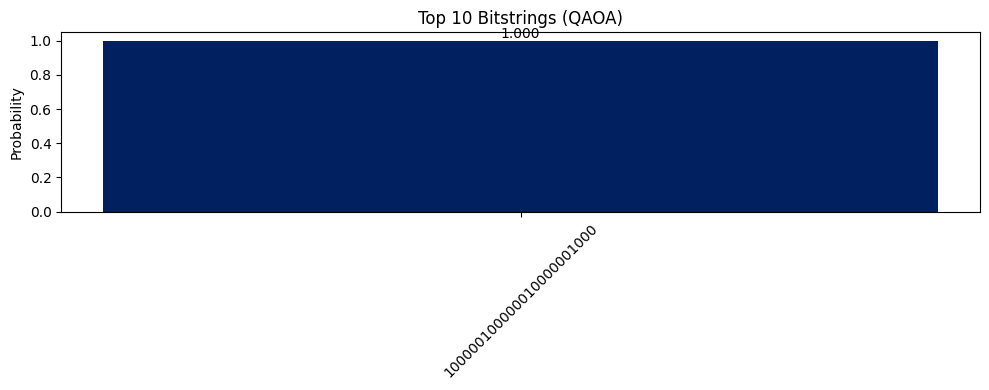

In [24]:
sorted_counts = sorted(counts.items(), key=lambda x: -x[1])
bit_labels = [x[0] for x in sorted_counts[:10]]
bit_counts = [x[1] for x in sorted_counts[:10]]

# Calculate total counts to convert counts into probabilities
total_counts = sum(x[1] for x in sorted_counts)
bit_probs = [count / total_counts for count in bit_counts]


reversed_bit_labels = [bit[::-1] for bit in bit_labels]

# Plot histogram with reversed bitstrings as x-axis labels
plt.figure(figsize=(10, 4))
bars = plt.bar(reversed_bit_labels, bit_probs, color='#002060')
plt.xticks(rotation=45)
plt.title("Top 10 Bitstrings (QAOA)")
plt.ylabel("Probability")
plt.tight_layout()

for bar, prob in zip(bars, bit_probs):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f"{prob:.3f}", ha='center', va='bottom')
plt.show()

In [26]:
import pandas as pd

# node_order must match the order used in the bitstrings
node_order = list(G.nodes)

index_to_nid_p = [
    labels[node].split("\n")[1].split("(")[1].split(")")[0]
    for node in node_order
]

index_to_nid_l = [
    labels[node].split("\n")[2].split("(")[1].split(")")[0]
    for node in node_order
]

# Build table with reversed bitstrings
bitstring_table = []
for bitstring, count in sorted_counts:
    reversed_bitstring = bitstring[::-1]  # Reverse the bitstring first
    selected_indices = [i for i, bit in enumerate(reversed_bitstring) if bit == '1']
    selected_nids_l = [index_to_nid_l[i] for i in selected_indices]
    selected_nids_p = [index_to_nid_p[i] for i in selected_indices]
    bitstring_table.append({
        "Bitstring": reversed_bitstring,
        "Selected in the Ligand": selected_nids_l,
        "Selected in the Protein": selected_nids_p,
        "Count": count,
        "Probability": count / total_counts
    })

# Convert to DataFrame
df = pd.DataFrame(bitstring_table)

# Display all rows
pd.set_option('display.max_rows', None)
print(df)

                  Bitstring Selected in the Ligand Selected in the Protein  \
0  100000100000010000001000    [D9, H15, H16, H17]        [D1, H2, H3, H4]   

   Count  Probability  
0   1024          1.0  


In [27]:
df.to_csv("F:Desktop\\QAOA 5.08.25\\Ligand Novobiocin February\\Iterations\\3H_0A_1D-NEW2\\results_3H_0A_1D-NEW2_with_4_features_iter_1.csv", index=False)
print("Results saved")

Results saved


C:\Users\80032128\AppData\Local\Temp\ipykernel_43472\3929692971.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


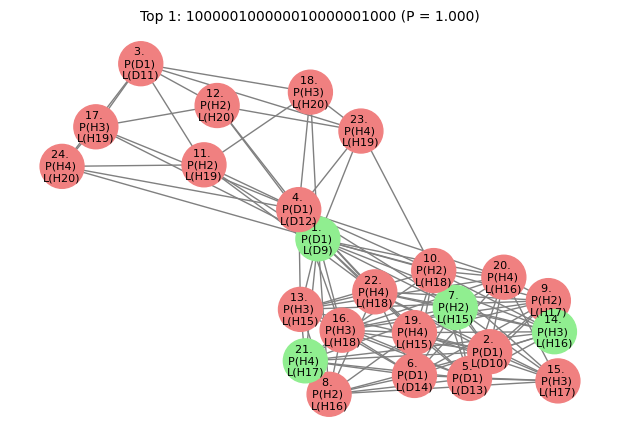

In [28]:
def plot_result(G, bitstring, title=None):
    x = [int(char) for char in bitstring]
    colors = ["lightcoral" if v == 0 else "lightgreen" for v in x]

    def densify_positions(pos, scale=0.6, center=(0.0, 0.0)):
        cx, cy = center
        return {n: (cx + (x - cx) * scale, cy + (y - cy) * scale) for n, (x, y) in pos.items()}

    pos = nx.spring_layout(G, seed=42)
    dense_pos = densify_positions(pos, scale=0.6)

    plt.figure(figsize=(6, 4))
    nx.draw(
        G, dense_pos,
        with_labels=True,
        labels=labels,
        node_color=colors,
        node_size=1000,
        edge_color='grey',
        font_size=8
    )
    if title:
        plt.title(title, fontsize=10)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

for idx, (bitstring, prob) in enumerate(zip(reversed_bit_labels, bit_probs), start=1):
    title = f"Top {idx}: {bitstring} (P = {prob:.3f})"
    plot_result(G, bitstring, title=title)